# Joint pressure and event-time forecasting

Compare continuation error and threshold timing at the ten-cycle landmark.
Internal estimates pool out-of-fold predictions within each repeat, then average
the three repeat estimates.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:06:55+00:00
Inputs: included aggregate tables and public external extracts


## Joint point errors

,tests,events,curve_rmse,onset_logmae,noncrossing
model,,,,,
DPI-EVT +A,812,490,0.1069,0.5863,0.1224
DPI-EVT,812,490,0.1208,0.6767,0.1327
EVT-NeuralSSM,812,490,0.1197,0.7888,0.1612
Transformer matched +A/crossing loss,812,490,0.1017,0.6234,0.0850
Transformer +cummax,812,490,0.1041,1.0826,0.2313
Threshold-projected Transformer/GBM,812,490,0.0999,0.2003,0.0238
Time-warped Transformer/GBM,812,490,0.2130,0.2007,0.0238
GBM horizon mixture,812,490,NaN,0.2003,NaN
Cox PH,812,490,NaN,0.3098,NaN


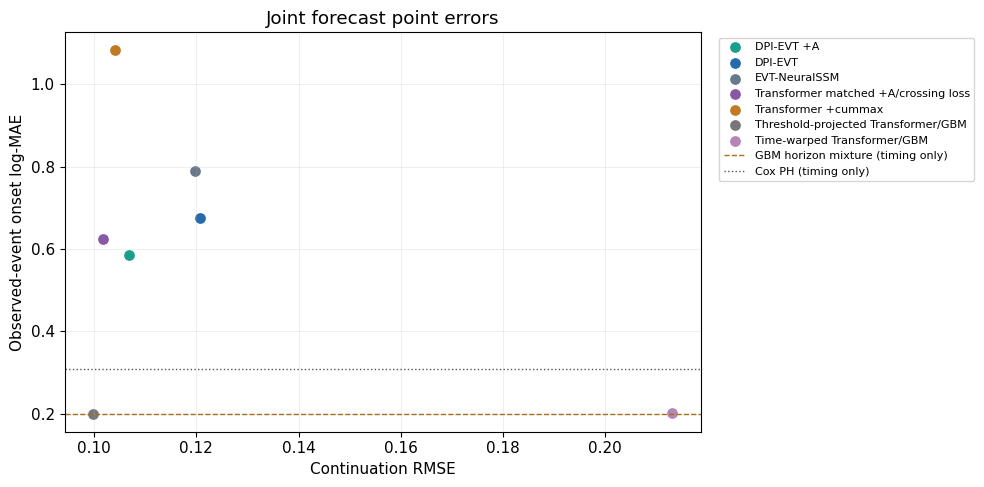

In [2]:
joint = pd.read_csv(TABLES / "joint_metrics.csv")
internal = joint[joint.source.eq("internal")].set_index("model")
order = ["DPI-EVT +A", "DPI-EVT", "EVT-NeuralSSM", "Transformer matched +A/crossing loss",
         "Transformer +cummax", "Threshold-projected Transformer/GBM", "Time-warped Transformer/GBM",
         "GBM horizon mixture", "Cox PH"]
display(internal.loc[order, ["tests", "events", "curve_rmse", "onset_logmae", "noncrossing"]].round(4))
fig, ax = plt.subplots(figsize=(10,5))
for name in order:
    row=internal.loc[name]
    if pd.notna(row.curve_rmse):
        ax.scatter(row.curve_rmse,row.onset_logmae,s=45,color=COLORS[name],label=name)
for name in ["GBM horizon mixture", "Cox PH"]:
    ax.axhline(internal.loc[name,"onset_logmae"],color=COLORS[name],linestyle="--" if name.startswith("GBM") else ":",linewidth=1,label=name+" (timing only)")
ax.set(xlabel="Continuation RMSE",ylabel="Observed-event onset log-MAE",title="Joint forecast point errors")
ax.legend(bbox_to_anchor=(1.02,1),loc="upper left",fontsize=8)
fig.tight_layout();plt.show()

## Paired uncertainty and native distribution scores

Sites are the internal resampling units. Intervals that include one do not establish equivalence. Native event-distribution scores are separate from the residual interval calibration.

In [3]:
paired = pd.read_csv(TABLES / "internal_paired_bootstrap.csv")
display(paired[["reference","comparator","metric","ratio","ratio_lo","ratio_hi"]].round(4))
native = pd.read_csv(TABLES / "internal_bootstrap.csv")
display(native[["model","traj_rmse_continuation","event_log_err","native_ibs"]].round(4))

,reference,comparator,metric,ratio,ratio_lo,ratio_hi
0,DPI-EVT +A,Transformer +cummax,onset_logmae,0.5416,0.3665,0.9356
1,DPI-EVT +A,Transformer +cummax,curve_rmse,1.0272,0.9081,1.1703
2,DPI-EVT,Transformer +cummax,onset_logmae,0.6251,0.4693,0.9717
3,DPI-EVT,Transformer +cummax,curve_rmse,1.1607,0.9919,1.3521
4,DPI-EVT +A,EVT-NeuralSSM,onset_logmae,0.7433,0.5879,0.9973
5,DPI-EVT +A,EVT-NeuralSSM,curve_rmse,0.8929,0.8290,0.9840
6,DPI-EVT +A,Transformer +A,onset_logmae,0.5087,0.3299,0.8694
7,DPI-EVT +A,Transformer +A,curve_rmse,0.9812,0.8924,1.1098
8,DPI-EVT +A,Time-warped Transformer/GBM,onset_logmae,2.9218,1.7621,4.9129
9,DPI-EVT +A,Time-warped Transformer/GBM,curve_rmse,0.5018,0.3940,0.6517


,model,traj_rmse_continuation,event_log_err,native_ibs
0,DPI-EVT,0.1208,0.6767,0.1041
1,EVT-NeuralSSM,0.1197,0.7888,NaN
2,Transformer,0.1040,1.0879,NaN
3,Transformer +cummax,0.1041,1.0826,NaN
4,Transformer +isotonic (diagnostic),0.1042,1.4894,NaN
5,GP prefix (linear + SE),0.3543,2.7632,0.3432
6,GBM horizon mixture,NaN,0.2003,0.0286
7,Cox PH,NaN,0.3098,0.0640
8,DPI-EVT +A,0.1069,0.5863,0.0987
9,DPI-EVT +C,0.1149,1.0576,0.1911


## Comparing the two outputs

The anchored decoder and the matched anchored Transformer have close point errors.
The threshold-projected hybrid has lower internal errors for both outputs, while
the time-warped hybrid improves timing at the cost of a higher curve error.